# 09 · Heston, rewritten: pricer, calibration, timing and hedges (plan §16.5)

**The course library's pricer.** Its integration uses 256 nodes whatever the range. At typical parameters it is accurate, but at corners of the lecture's bounds it is off by 6–46 vol points: large ξ, short τ, ρ near −1, slow κ.
- **The project's `heston.py`** uses the same formula, Lewis's with the Black–Scholes control variate, with node counts tied to the range. It precomputes the strike terms per session and returns C_S and C_v in closed form.
- **Its accuracy:** within 0.0086 vol points of an adaptive-quadrature reference everywhere tested (`tests/test_heston.py`).

**Calibration B2** keeps calibration B's sample and bounds and changes the solver:
- vega-weighted price errors in place of IV errors;
- two starts per session (yesterday's solution and an at-the-money start);
- a coarse-grid search, then a polish on the accurate grid.

**Hedges, 2010–2023:**
- H_model = C_S, Heston's own delta;
- H_mv = C_S + (ρξ/S)·C_v, the model's minimum-variance delta;
- H_fit = C_S + β̂·C_v/S, with β̂ fitted on the trailing 12 months.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

## The integration defect, live: a 14-day put at K/S = 0.6 with ξ = 5

In [2]:
from erdos_quant_finance_project.lecture import option_pricing
from erdos_quant_finance_project import heston as H
op = option_pricing(); S, K, r, q, t = 3000.0, 1800.0, 0.02, 0.018, 14 / 365
p = np.array([0.03, 10.0, 0.04, 5.0, -0.7])
fwd = K * np.exp(-r * t) - S * np.exp(-q * t)
rows = [{"pricer": f"library, {n} nodes", "put": op.heston_call(S, K, *p[[0]], r, t, *p[1:], q, n_phi=n, check_bounds=False) + fwd} for n in (256, 512, 4096)]
ch = H.Chain(S, [K], [t], [r], [q], [-1.0], [p])
rows.append({"pricer": "heston.py", "put": ch.prices(p)[0]})
pd.DataFrame(rows)

,pricer,put
0,"library, 256 nodes",0.063665
1,"library, 512 nodes",0.022328
2,"library, 4096 nodes",0.022328
3,heston.py,0.022328


## Timing: the old calibration against B2, the same 21 sessions, run alone

In [3]:
bm = pd.read_csv(R / "heston2/benchmark.csv")
bm.groupby("method")[["wall_s", "cpu_s", "iv_rmse"]].agg(["median", "sum", "max"]).round(2)

wall_s                   cpu_s                  iv_rmse            
                                   median      sum     max median      sum     max  median   sum   max
method                                                                                                
B2 (project pricer, 2 cold starts)   5.67   114.63    9.46   5.69   113.59    9.31    0.02  0.52  0.05
old B (library, 3 starts)           17.48  2279.98  610.42  17.22  2246.20  598.70    0.02  0.43  0.04

In [4]:
P2 = pd.concat([pd.read_csv(f, parse_dates=["session"]) for f in sorted((R / "heston2").glob("params_*.csv"))])
P2.groupby(P2.session.dt.year).agg(sessions=("n", "size"), converged=("ok", "sum"), cpu_median_s=("cpu_s", "median"),
    iv_rmse_median=("iv_rmse", "median"), at_bound=("at_bound", "sum"), accuracy_check_max_vp=("accuracy_check_vp", "max")).round(4)

,sessions,converged,cpu_median_s,iv_rmse_median,at_bound,accuracy_check_max_vp
session,,,,,,
2010,242,242,0.7656,0.0157,90,0.0000
2011,245,245,0.8125,0.0153,93,0.0000
2012,248,248,1.3125,0.0148,14,0.0000
2013,252,252,1.7734,0.0134,75,0.0000
2014,249,249,2.5781,0.0173,217,0.0000
2015,252,252,3.8359,0.0215,76,0.0001
2016,251,251,4.6719,0.0189,19,0.0000
2017,250,250,11.3984,0.0130,173,0.0000
2018,251,251,7.2812,0.0225,197,0.0000


**Reading.**
- **Every one of the 3,479 sessions of 2010–2023 converged.** The old calibration failed on 49 of 497 sessions, all at scipy's 500-evaluation cap.
- **Speed:** on the benchmark, B2 is 3× faster at the median and 20× faster in total.
- **Accuracy:** at most 0.007 vol points.
- **κ still hits its bound of 10 on 37% of sessions,** which is Heston's misfit to the SPX skew, not a solver failure.

## Hedging, 2010–2023

In [5]:
hg = pd.read_csv(R / "heston2/gains_by_year.csv")
hg.pivot_table(index="year", columns=["rule", "base", "cp"], values="gain").round(2)

rule H_fit                               H_model          H_mv                                  R2      
base  H_mv          R1          R2            R1       H_model          R1          R2          R1      
cp       C     P     C     P     C     P       C     P       C     P     C     P     C     P     C     P
year                                                                                                    
2010   NaN   NaN   NaN   NaN   NaN   NaN   -1.37 -1.26    0.63  0.62  0.12  0.15   NaN   NaN   NaN   NaN
2011 -0.45 -0.21 -0.20 -0.16 -0.58 -0.37   -1.35 -0.98    0.65  0.51  0.17  0.04 -0.09 -0.14  0.24  0.15
2012 -0.49 -0.31 -1.37 -0.83 -1.45 -1.01   -1.34 -1.35    0.32  0.41 -0.59 -0.40 -0.64 -0.54  0.03  0.09
2013  0.14  0.06 -0.06 -0.08 -0.25 -0.28   -1.22 -1.46    0.44  0.53 -0.23 -0.14 -0.45 -0.35  0.15  0.15
2014  0.31  0.21 -0.04 -0.05 -0.28 -0.33   -1.51 -1.98    0.40  0.55 -0.51 -0.33 -0.86 -0.68  0.19  0.21
2015  0.11 -0.20 -0.19 -0.15 -0.60 -0.58   -2.23 -1.98    0.59  0.68 -0.34  0.04 -0.79 -0.32  0.25  0.28
2016  0.30  0.15 -0.11 -0.17 -0.35 -0.38   -2.01 -1.97    0.48  0.54 -0.58 -0.37 -0.93 -0.62  0.18  0.15
2017  0.42  0.52 -0.21 -0.25 -0.38 -0.31   -1.28 -1.42    0.08 -0.07 -1.11 -1.58 -1.40 -1.72  0.12  0.05
2018  0.06 -0.21 -0.13 -0.13 -0.17 -0.20   -1.20 -1.22    0.45  0.58 -0.20  0.07 -0.24  0.01  0.03  0.06
2019  0.14  0.05 -0.02 -0.07 -0.15 -0.19   -1.70 -1.78    0.56  0.60 -0.18 -0.12 -0.33 -0.25  0.12  0.10
2020 -0.52 -0.33 -0.42 -0.29 -0.74 -0.46   -1.30 -1.06    0.59  0.53  0.07  0.03 -0.15 -0.10  0.19  0.12
2021  0.12  0.05 -0.06 -0.08 -0.25 -0.29   -1.10 -1.18    0.43  0.48 -0.20 -0.14 -0.42 -0.36  0.15  0.16
2022  0.06  0.05 -0.68 -0.70 -0.68 -0.61   -1.68 -1.55    0.33  0.30 -0.79 -0.79 -0.79 -0.69  0.00 -0.06
2023  0.36  0.38 -0.13 -0.22 -0.14 -0.20   -0.67 -0.88   -0.05 -0.05 -0.76 -0.96 -0.76 -0.94  0.00 -0.01

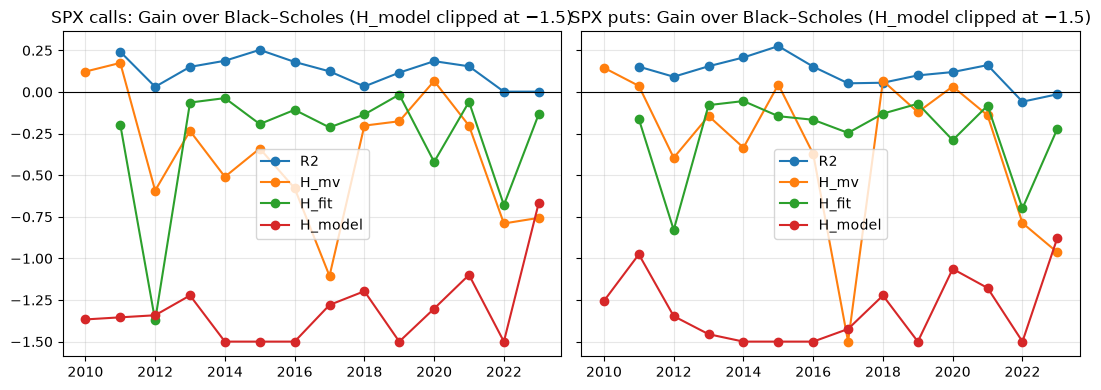

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cp, nm in zip(axes, "CP", ("calls", "puts")):
    for rule in ("R2", "H_mv", "H_fit", "H_model"):
        x = hg[(hg.rule == rule) & (hg.base == "R1") & (hg.cp == cp)].sort_values("year")
        ax.plot(x.year, x.gain.clip(lower=-1.5), marker="o", label=rule)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"SPX {nm}: Gain over Black–Scholes (H_model clipped at −1.5)"); ax.legend()
plt.tight_layout()

In [7]:
bt = pd.read_csv(R / "heston2/beta.csv")
bt.groupby(["year", "cp"])[["beta", "rho_xi_median_month"]].median().unstack().round(3)

beta        rho_xi_median_month       
cp        C      P                   C      P
year                                         
2011 -1.174 -1.244              -1.317 -1.325
2012 -1.210 -1.118              -0.893 -0.893
2013 -0.522 -0.558              -0.780 -0.780
2014 -0.532 -0.617              -1.186 -1.224
2015 -0.774 -0.855              -1.101 -1.101
2016 -0.793 -0.899              -1.024 -1.024
2017 -0.650 -0.688              -1.332 -1.345
2018 -0.981 -1.161              -1.678 -1.678
2019 -0.856 -0.960              -1.264 -1.264
2020 -2.033 -2.007              -2.111 -2.111
2021 -1.505 -1.564              -2.524 -2.525
2022 -0.962 -0.968              -1.012 -1.012
2023 -0.437 -0.417              -1.147 -1.147

**Reading.**
- **Heston's own delta has 1.7–3.2 times Black–Scholes' squared error, every year.**
- **The minimum-variance correction recovers much of that.** It ends near Black–Scholes and never beats R2.
- **Fitting the scale β̂ to data instead of the calibrated ρξ** helps against H_mv in most years but still loses to R2. β̂ is typically 40–100% of ρξ.
- **So the fault is in the shape of Heston's sensitivities across strikes and maturities,** not in their scale. That extends Hull and White's finding for SABR.